Ұяшық 5.1. Сенімділік шегін val жиынынан анықтау

In [2]:
# Ұяшық 5.1 (түзетілген) — conf шегін val жиынында анықтау + тұрақтылық тексерісі
import json, time
import numpy as np
from pathlib import Path
from ultralytics import YOLO

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
BEST = PROJECT_ROOT / "runs" / "main_yolo26n_640_e30_s42" / "weights" / "best.pt"
DATA_YAML = PROJECT_ROOT / "configs" / "data.yaml"
THR_FILE = PROJECT_ROOT / "configs" / "threshold.json"
REF_MAP50, REF_MAP, TOL = 0.591, 0.274, 0.002   # 4.6 нәтижесі

model = YOLO(str(BEST))
t0 = time.time()
m = model.val(
    data=str(DATA_YAML), split="val", imgsz=640, batch=16,
    device=0, workers=2, plots=False, verbose=False,
    project=str(PROJECT_ROOT / "runs"), name="val_threshold_tmp", exist_ok=True,
)
print(f"Бағалау уақыты: {time.time() - t0:.1f} с")

box = m.box
print(f"mAP50 = {box.map50:.4f} (эталон {REF_MAP50}), mAP50-95 = {box.map:.4f} (эталон {REF_MAP})")
ok = abs(box.map50 - REF_MAP50) <= TOL and abs(box.map - REF_MAP) <= TOL
print("Тұрақтылық тексерісі:", "✅ өтті" if ok else "❌ өтпеді, шек САҚТАЛМАЙДЫ")

px = np.asarray(box.px)
f1 = np.asarray(box.f1_curve)
f1_mean = f1.mean(axis=0)
i = int(f1_mean.argmax())
conf_best = float(px[i])
p_i = float(np.asarray(box.p_curve).mean(axis=0)[i])
r_i = float(np.asarray(box.r_curve).mean(axis=0)[i])
print(f"\nОрташа F1 ең жоғары: {f1_mean[i]:.3f}, conf = {conf_best:.3f}")
print(f"Осы шекте орташа P = {p_i:.3f}, R = {r_i:.3f}  (4.6 кестесі: 0.616 / 0.545)")

for k, name in m.names.items():
    j = int(f1[k].argmax())
    print(f"  {name}: F1 = {f1[k, j]:.3f}, conf = {px[j]:.3f}")

if ok:
    THR_FILE.write_text(json.dumps({
        "conf": round(conf_best, 3),
        "selected_on": "val",
        "rule": "max mean F1 over classes",
        "model": str(BEST),
    }, indent=2), encoding="utf-8")
    print("\nСақталды:", THR_FILE)

Ultralytics 8.4.191  Python-3.12.10 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce GTX 1650 Ti, 4096MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 197.2±35.2 MB/s, size: 73.9 KB)
val: Scanning D:\road_damage_yolo\data\yolo_dataset\labels\val.cache... 864 images, 79 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 864/864  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 54/54 4.4it/s 12.3s0.1s
                   all        864       1592      0.616      0.545      0.591      0.274
Speed: 0.9ms preprocess, 5.7ms inference, 0.0ms loss, 1.0ms postprocess per image
Бағалау уақыты: 12.8 с
mAP50 = 0.5914 (эталон 0.591), mAP50-95 = 0.2741 (эталон 0.274)
Тұрақтылық тексерісі: ✅ өтті

Орташа F1 ең жоғары: 0.581, conf = 0.239
Осы шекте орташа P = 0.606, R = 0.559  (4.6 кестесі: 0.616 / 0.545)
  D00: F1 = 0.555, conf = 0.230
  D10: F1 = 0.524, conf = 0.222


Ұяшық 5.2. Шынайы белгі мен болжамды қатар көрсету (val)

conf шегі: 0.239


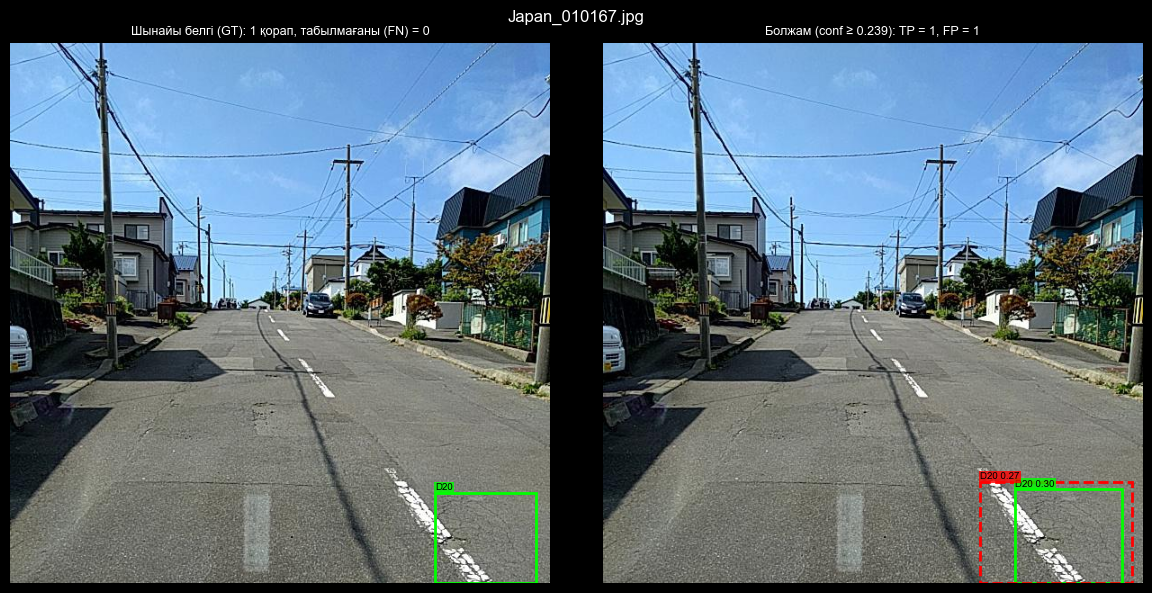

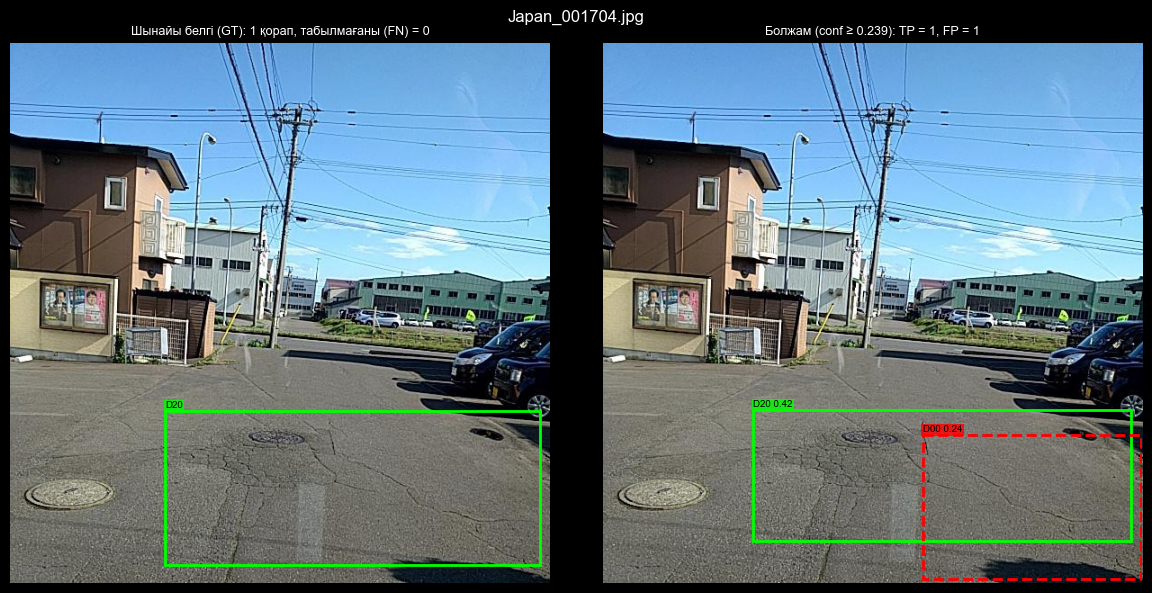

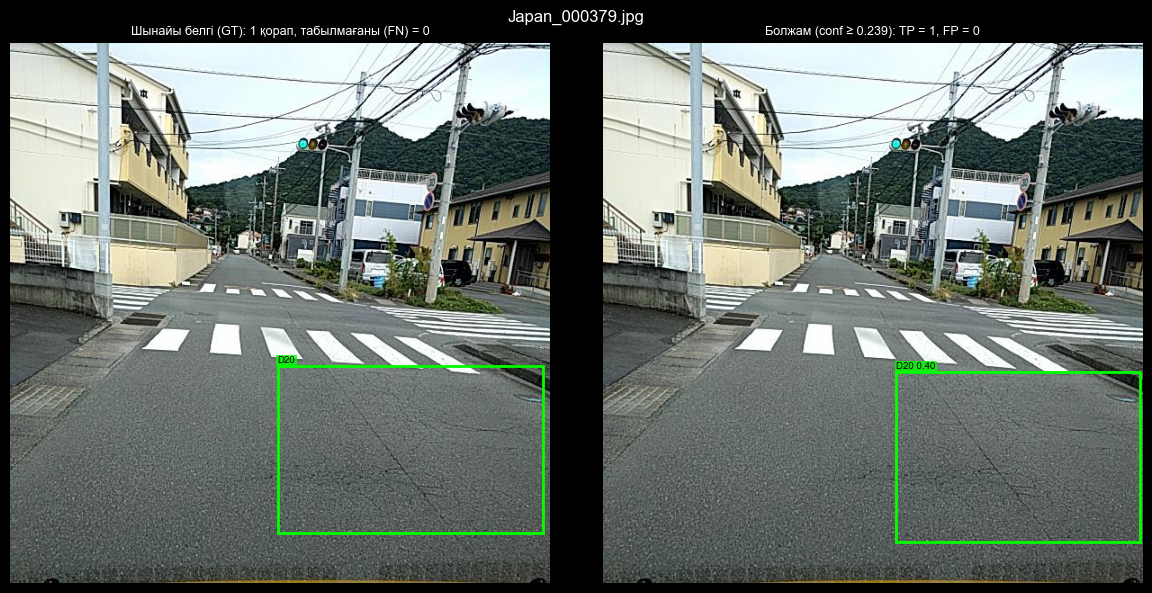

           image    size  n_gt  n_pred  TP  FP  FN
Japan_010167.jpg 600x600     1       2   1   1   0
Japan_001704.jpg 600x600     1       2   1   1   0
Japan_000379.jpg 600x600     1       1   1   0   0
Japan_011628.jpg 600x600     3       2   2   0   1
Japan_004309.jpg 600x600     1       2   1   1   0
Japan_003811.jpg 600x600     1       4   0   4   1
Japan_003539.jpg 600x600     2       1   1   0   1
Japan_002116.jpg 600x600     0       1   0   1   0
Japan_011507.jpg 600x600     1       3   1   2   0
Japan_001558.jpg 600x600     1       1   1   0   0
Japan_010742.jpg 600x600     1       1   1   0   0
Japan_011560.jpg 600x600     1       2   1   1   0

Қосынды: {'n_gt': 14, 'n_pred': 22, 'TP': 11, 'FP': 11, 'FN': 3}
Суреттер: D:\road_damage_yolo\results\predictions\val_samples


In [3]:
# Ұяшық 5.2 — GT мен болжамды қатар визуализациялау (val, кездейсоқ 12 сурет)
import json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image
from ultralytics import YOLO

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
BEST = PROJECT_ROOT / "runs" / "main_yolo26n_640_e30_s42" / "weights" / "best.pt"
DS = PROJECT_ROOT / "data" / "yolo_dataset"
OUT_DIR = PROJECT_ROOT / "results" / "predictions" / "val_samples"
TAB_DIR = PROJECT_ROOT / "results" / "tables"
OUT_DIR.mkdir(parents=True, exist_ok=True)

THR = json.loads((PROJECT_ROOT / "configs" / "threshold.json").read_text(encoding="utf-8"))["conf"]
NAMES = {0: "D00", 1: "D10", 2: "D20", 3: "D40"}
IOU_THR = 0.5
N_SAMPLES = 12
N_SHOW = 3
print("conf шегі:", THR)

def read_gt(img_path, w, h):
    """YOLO .txt -> [(class, x1, y1, x2, y2)] пиксельмен"""
    lbl = DS / "labels" / "val" / (img_path.stem + ".txt")
    boxes = []
    if lbl.exists():
        for line in lbl.read_text().splitlines():
            p = line.split()
            if len(p) != 5:
                continue
            c = int(p[0]); xc, yc, bw, bh = map(float, p[1:])
            boxes.append((c, (xc - bw/2)*w, (yc - bh/2)*h, (xc + bw/2)*w, (yc + bh/2)*h))
    return boxes

def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0.0

def match(gt, pr):
    """pr conf бойынша кемуі ретімен; бір GT тек бір болжамға сәйкес келеді"""
    used, pr_tp = set(), []
    for c, cf, *bb in pr:
        best, bj = 0.0, -1
        for j, (gc, *gb) in enumerate(gt):
            if j in used or gc != c:
                continue
            v = iou(bb, gb)
            if v > best:
                best, bj = v, j
        if best >= IOU_THR:
            used.add(bj); pr_tp.append(True)
        else:
            pr_tp.append(False)
    return pr_tp, [j in used for j in range(len(gt))]

def draw(ax, img, boxes, ok_flags, title, with_conf=False):
    ax.imshow(img); ax.set_title(title, fontsize=9); ax.axis("off")
    for b, ok in zip(boxes, ok_flags):
        if with_conf:
            c, cf, x1, y1, x2, y2 = b; txt = f"{NAMES[c]} {cf:.2f}"
        else:
            c, x1, y1, x2, y2 = b; txt = NAMES[c]
        col = "lime" if ok else "red"
        ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False,
                                       ec=col, lw=2, ls="-" if ok else "--"))
        ax.text(x1, y1 - 3, txt, fontsize=7, color="black",
                bbox=dict(fc=col, alpha=0.8, pad=1, lw=0))

model = YOLO(str(BEST))
imgs = sorted((DS / "images" / "val").glob("*.jpg"))
sample = random.Random(42).sample(imgs, N_SAMPLES)

rows = []
for k, p in enumerate(sample):
    img = np.array(Image.open(p).convert("RGB"))
    h, w = img.shape[:2]
    gt = read_gt(p, w, h)
    r = model.predict(str(p), conf=THR, imgsz=640, device=0, verbose=False)[0]
    pr = [(int(c), float(cf), *map(float, xy)) for c, cf, xy in
          zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())]
    pr.sort(key=lambda t: -t[1])

    pr_tp, gt_found = match(gt, pr)
    tp = sum(pr_tp); fp = len(pr) - tp; fn = len(gt) - sum(gt_found)
    rows.append({"image": p.name, "size": f"{w}x{h}", "n_gt": len(gt),
                 "n_pred": len(pr), "TP": tp, "FP": fp, "FN": fn})

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    draw(axes[0], img, gt, gt_found, f"Шынайы белгі (GT): {len(gt)} қорап, табылмағаны (FN) = {fn}")
    draw(axes[1], img, pr, pr_tp, f"Болжам (conf ≥ {THR}): TP = {tp}, FP = {fp}", with_conf=True)
    fig.suptitle(p.name)
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"{p.stem}_gt_vs_pred.png", dpi=120)
    if k < N_SHOW:
        plt.show()
    else:
        plt.close(fig)

df = pd.DataFrame(rows)
print(df.to_string(index=False))
print("\nҚосынды:", df[["n_gt", "n_pred", "TP", "FP", "FN"]].sum().to_dict())
df.to_csv(TAB_DIR / "val_samples_tp_fp_fn.csv", index=False)
print("Суреттер:", OUT_DIR)